# Tentativo 16 · I risultati

**Che cosa abbiamo fatto**
- **Dataset**: testate politiche, testo estratto con trafilatura (modalità precisione), articoli tra 100 e 1.500 parole
  (entrano interi in 2.048 token), doppioni tolti tra tutte le testate, **una testata per gruppo** Owner/Parent Domain.
- **TF-IDF** (il riferimento): parole e coppie di parole + modello lineare.
- **Embedding congelati**: Qwen3-Embedding (0,6B e 8B), senza addestramento, + lo stesso modello lineare.
- **ModernBERT** addestrato: articoli interi a 2.048 token, tutti gli articoli, 5 epoche.

Ogni modello in due impostazioni: **classificazione a 5 classi** e **regressione sul punteggio** NewsGuard (0–100).
Stessi 5 fold per tutti.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import funzioni as F

warnings.filterwarnings("ignore")
OUT = Path("Results/confronto"); OUT.mkdir(parents=True, exist_ok=True)
FONTI = {"TF-IDF": "Results/feature", "Embedding Qwen3 0.6B": "Results/embedding/Qwen3-Embedding-0.6B",
         "Embedding Qwen3 8B": "Results/embedding/Qwen3-Embedding-8B", "ModernBERT 2048": "Results/modernbert"}
T = {nome: pd.read_csv(Path(c) / "previsioni_testate.csv", index_col=0) for nome, c in FONTI.items()
     if (Path(c) / "previsioni_testate.csv").exists()}
t = pd.read_csv(F.DATASET / "testate.csv", index_col="domain")
print(f"{t.articoli.sum():,} articoli di {len(t)} testate · per livello: " + ", ".join(f"{l} {n}" for l, n in t.livello.value_counts().sort_index().items()))
print("modelli con i risultati:", ", ".join(T))

25,524 articoli di 226 testate · per livello: l1 35, l2 43, l3 30, l4 79, l5 39
modelli con i risultati: TF-IDF, Embedding Qwen3 0.6B, Embedding Qwen3 8B, ModernBERT 2048


## 1. Il confronto

Quattro misure: **F1** sui 5 livelli, **tolerant ±1** (giusto anche se sbaglia di un livello), e l'accuratezza nel dire
se una testata è **affidabile** (punteggio ≥ 60), su tutte le testate e solo sulle estreme (l1, l2, l4, l5). In blu la
classificazione a 5 classi, in arancio la regressione; linee grigie: intervalli al 95%.

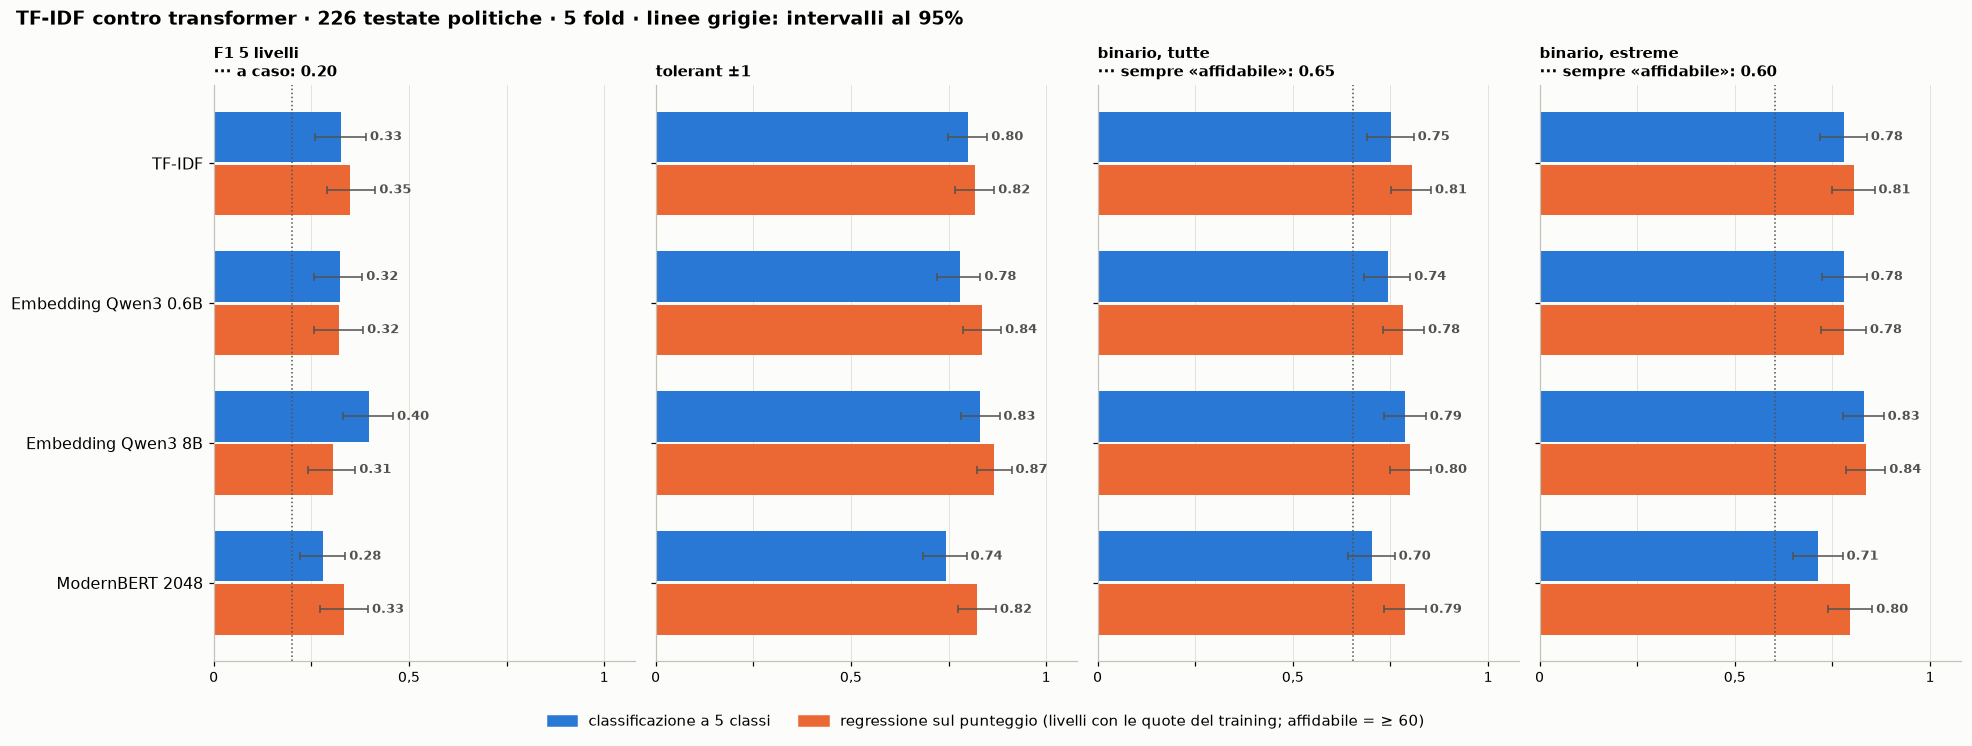

In [2]:
valori, intervalli, differenze, vero = F.misure_modelli(T)
valori.to_csv(OUT / "confronto.csv")
F.grafico_confronto(valori, intervalli, vero, OUT / "confronto.png")

### Lo stesso grafico, con i dettagli

Accanto ai nomi che cosa è ogni modello, nei titoli su quali testate si misura, sotto come si addestra e come si testa.
La **baseline** è il valore di chi risponde sempre allo stesso modo senza leggere i testi: per «affidabile sì/no» è dire
sempre «affidabile», cioè la quota di testate affidabili (0,65 su tutte, 0,60 sulle estreme). Un modello serve solo se
sta sopra.

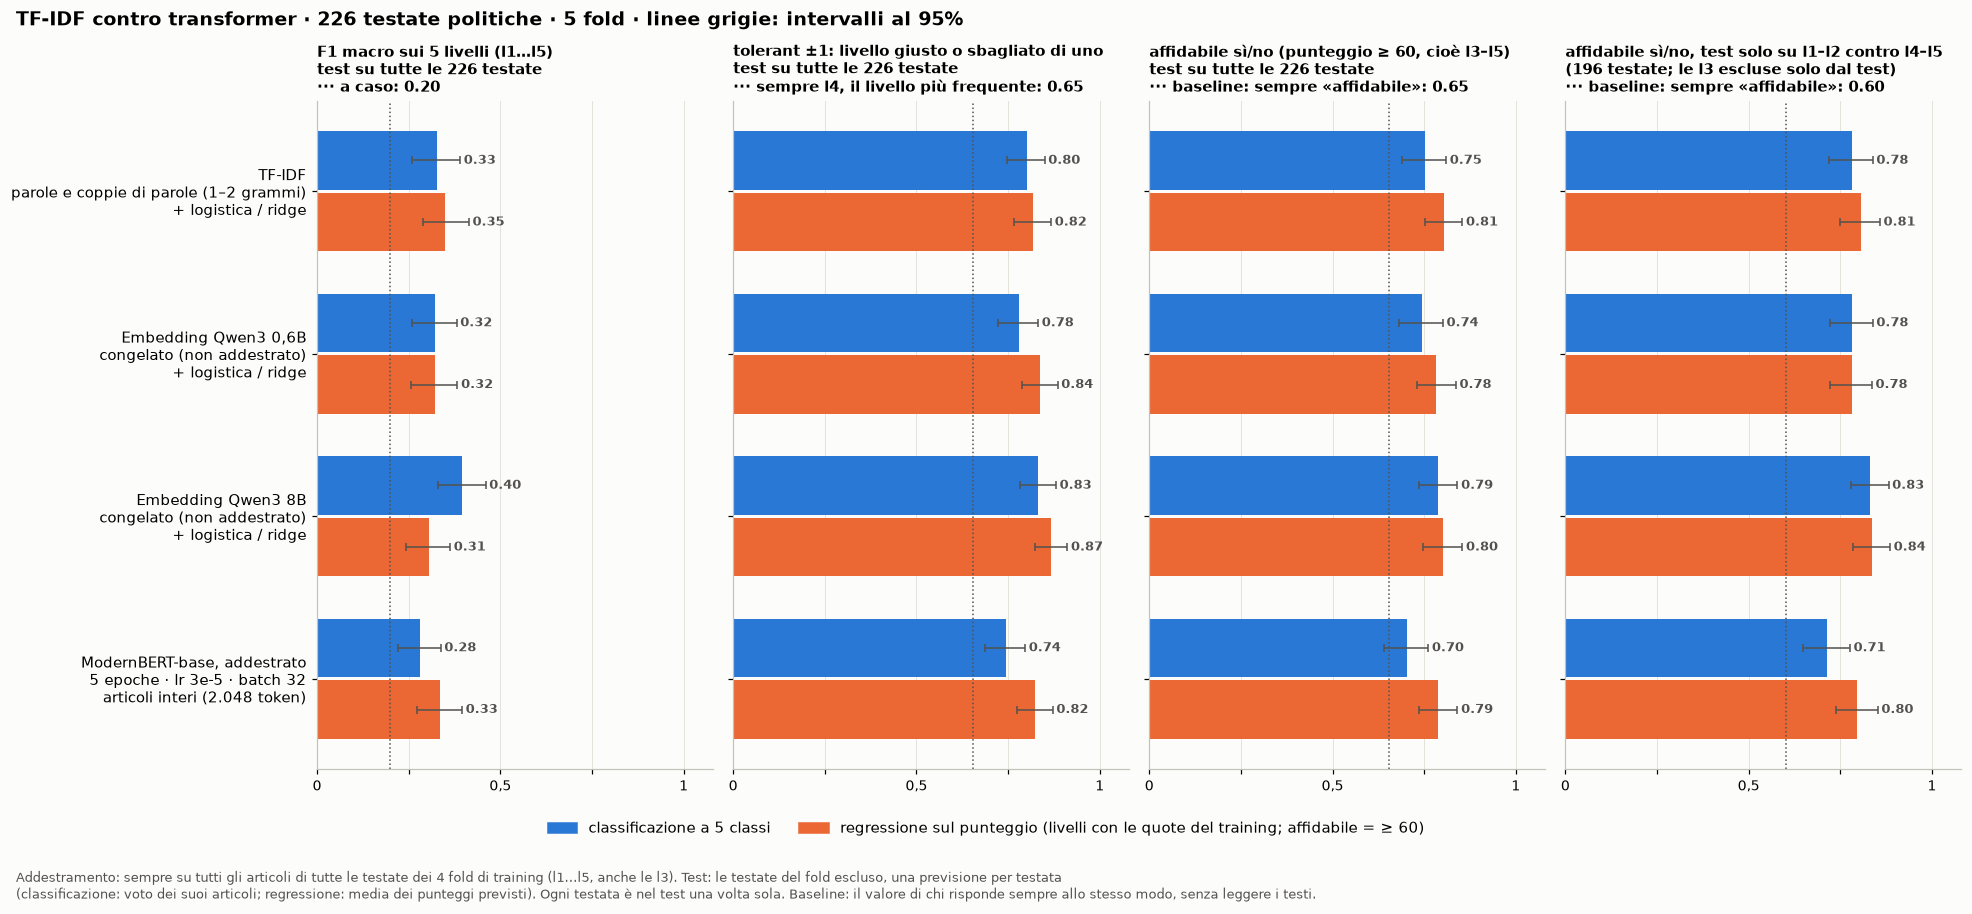

In [3]:
F.grafico_confronto(valori, intervalli, vero, OUT / "confronto_dettagli.png", dettagli=True)

## 2. In numeri
In alto i valori; sotto la differenza da TF-IDF con la stessa impostazione (è chiara se l'intervallo non contiene lo zero).

In [4]:
display(valori.round(3))
differenze if len(differenze) else "per ora c'è solo il TF-IDF"

F1 5 livelli  tolerant ±1  binario, tutte  \
TF-IDF               5 classi            0.327        0.801           0.752   
                     regressione         0.349        0.819           0.805   
Embedding Qwen3 0.6B 5 classi            0.322        0.779           0.743   
                     regressione         0.321        0.836           0.783   
Embedding Qwen3 8B   5 classi            0.397        0.832           0.788   
                     regressione         0.305        0.867           0.801   
ModernBERT 2048      5 classi            0.281        0.743           0.704   
                     regressione         0.334        0.823           0.788   

                                  binario, estreme  
TF-IDF               5 classi                0.781  
                     regressione             0.806  
Embedding Qwen3 0.6B 5 classi                0.781  
                     regressione             0.781  
Embedding Qwen3 8B   5 classi                0.832  
                     regressione             0.837  
ModernBERT 2048      5 classi                0.714  
                     regressione             0.796

Δ F1 5 livelli dal TF-IDF  \
Embedding Qwen3 0.6B 5 classi      -0.005 [-0.068; +0.062]   
                     regressione   -0.028 [-0.099; +0.040]   
Embedding Qwen3 8B   5 classi      +0.069 [-0.000; +0.141]   
                     regressione   -0.044 [-0.128; +0.033]   
ModernBERT 2048      5 classi      -0.046 [-0.123; +0.029]   
                     regressione   -0.015 [-0.092; +0.062]   

                                 Δ binario, tutte dal TF-IDF  
Embedding Qwen3 0.6B 5 classi        -0.009 [-0.071; +0.049]  
                     regressione     -0.022 [-0.066; +0.022]  
Embedding Qwen3 8B   5 classi        +0.035 [-0.018; +0.093]  
                     regressione     -0.004 [-0.058; +0.053]  
ModernBERT 2048      5 classi        -0.049 [-0.111; +0.009]  
                     regressione     -0.018 [-0.058; +0.022]

## 3. ModernBERT è addestrato abbastanza? La loss epoca per epoca

Per ogni fold, la loss di training dopo ognuna delle 5 epoche e, accanto, la stessa loss sugli articoli del fold di test
(testate mai viste), misurata dopo l'ultima epoca.
- **5 classi**: entropia incrociata, con classi bilanciate e label smoothing 0,1 come nell'addestramento. Due riferimenti:
  *a caso* (1/5 a ogni livello, 1,63) e il *minimo possibile* (circa 0,42). Con la label smoothing la loss non può
  arrivare a zero: il minimo è quello di un modello che ha imparato a memoria ogni articolo di training.
- **Regressione**: errore medio in punti NewsGuard (radice dell'errore quadratico); riferimento: dire sempre il
  punteggio medio del training (circa 28 punti).

Al centro e a destra il test per fold, ModernBERT contro TF-IDF; in alto a destra la diagnostica fatta prima dei 5 fold
(fold 2, 6 epoche, il test misurato dopo ogni epoca).

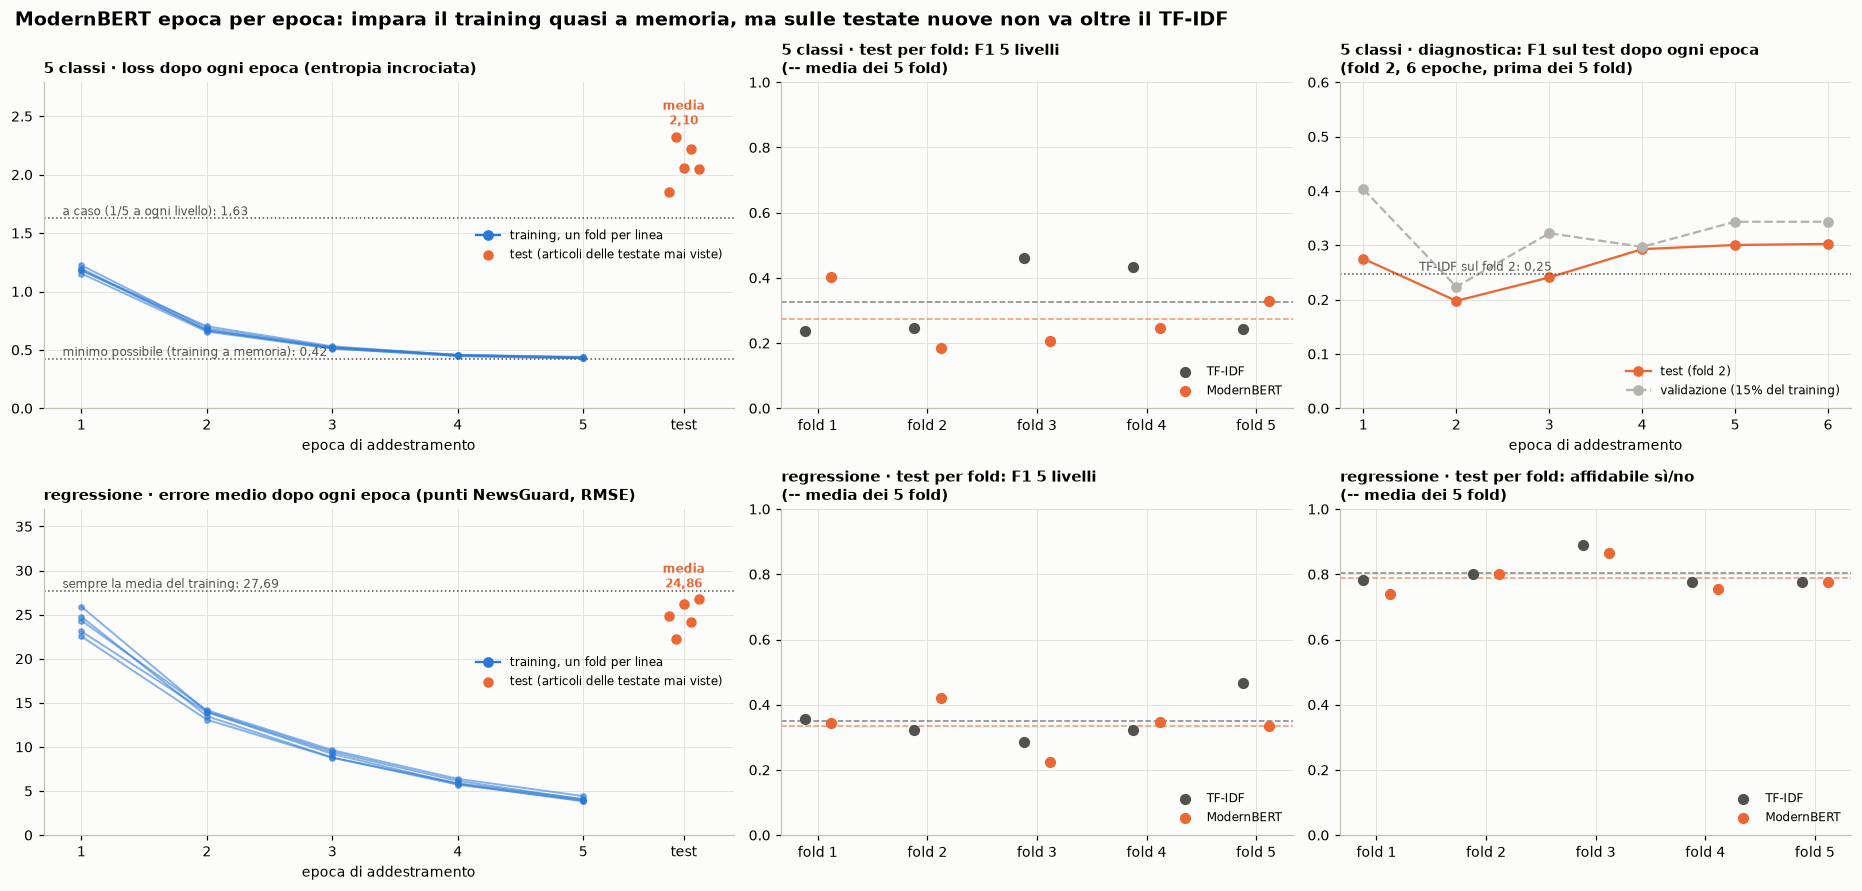

epoca 1  epoca 2  epoca 3  epoca 4  epoca 5  \
configurazione fold                                                
5 classi       1        1.22     0.68     0.52     0.46     0.44   
               2        1.20     0.67     0.51     0.45     0.43   
               3        1.18     0.67     0.52     0.46     0.44   
               4        1.15     0.66     0.51     0.45     0.43   
               5        1.18     0.70     0.53     0.46     0.43   
regressione    1       24.33    14.17     9.64     6.38     4.43   
               2       24.77    13.49     8.80     5.72     3.90   
               3       23.11    13.94     9.20     5.81     3.83   
               4       25.91    14.01     9.43     6.15     4.03   
               5       22.54    13.09     8.78     5.88     4.10   

                     test, dopo l'ultima epoca  \
configurazione fold                              
5 classi       1                          1.86   
               2                          2.33   
               3                          2.06   
               4                          2.22   
               5                          2.05   
regressione    1                         24.88   
               2                         22.29   
               3                         26.23   
               4                         24.11   
               5                         26.81   

                     minimo possibile (training a memoria)  \
configurazione fold                                          
5 classi       1                                      0.42   
               2                                      0.42   
               3                                      0.43   
               4                                      0.42   
               5                                      0.43   
regressione    1                                       NaN   
               2                                       NaN   
               3                                       NaN   
               4                                       NaN   
               5                                       NaN   

                     a caso (1/5 a ogni livello)  sempre la media del training  
configurazione fold                                                             
5 classi       1                            1.63                           NaN  
               2                            1.62                           NaN  
               3                            1.63                           NaN  
               4                            1.62                           NaN  
               5                            1.63                           NaN  
regressione    1                             NaN                         27.78  
               2                             NaN                         25.39  
               3                             NaN                         30.81  
               4                             NaN                         26.88  
               5                             NaN                         27.60

In [5]:
if (Path("Results/modernbert/regressione") / "fold1.csv").exists():
    L = F.loss_epoche("Results/modernbert", t)
    per_fold = F.misure_per_fold(T)
    f = Path("Results/modernbert/diagnostica/curva_fold2.csv")
    F.grafico_loss_epoche(L, per_fold, pd.read_csv(f) if f.exists() else None, OUT / "loss_epoche.png")
    L.to_csv(OUT / "loss_epoche.csv")
    display(L.round(2))
else:
    print("mancano le previsioni per articolo di ModernBERT (Results/modernbert/*/fold*.csv)")

**Che cosa vuol dire.** ModernBERT non è sottoallenato: dopo 5 epoche la loss di training è 0,43, quasi il minimo
possibile (0,42), e l'errore della regressione sul training è di 4 punti. Il training è imparato quasi a memoria.

Sul test invece la loss è circa 2,1, più alta che rispondendo a caso (1,63): sulle testate nuove il modello sbaglia
con sicurezza. L'errore della regressione è di circa 25 punti, poco meno dei 28 di chi dice sempre la media. Ogni
articolo eredita il livello della sua testata, quindi il modello impara a riconoscere le testate di training più che
un segnale che vale per testate nuove. Più epoche non servirebbero: nella diagnostica il test si ferma a 0,30 dalla 4ª
epoca, e per fold ModernBERT e TF-IDF si alternano.